# Weekend margining: financial analysis

**FRE-GY 6931 final project, Team 9.** Owner: Swastik Mishra. Contracts: Sai Kishore. First draft built with Claude Code; every assumption here is for the team to check and defend.

This notebook answers two questions with numbers:

1. How well does a Bitcoin perpetual hedge protect a position, and what do funding and liquidation cost?
2. What discount must the weekend vault charge, and is using it better than keeping margin in idle cash?

### Main results

| # | Result | Section |
|---|---|---|
| 1 | The hedge works at modest leverage. At the demo's 2.6x, it removes 92% of the variance of a 30-day BTC holding. A typical month earns about \$340 per BTC from funding and T-bill interest. The worst month in the data costs about \$1,400. | A |
| 2 | Liquidation is the main threat to a hedge. With no top-ups, the fund's short at 2.6x is liquidated in 14% of 30-day windows, and at 4.9x in about half. A liquidated hedge leaves the fund unhedged. | A, B |
| 3 | BTC is not riskier per hour over a weekend: hourly volatility is 0.52% inside closures against 0.68% outside. A closure is risky because it is long. Its 99% move is +11.1% and -13.0%, and the worst was about 20%. | C |
| 4 | **The 10bp discount covers the cost of each use (6.6bp in the base case) but not the cost of cash that waits.** A vault sized for 99% of weekends is used 18-25% on average and earns 1.2-1.7% a year against 4.01% on T-bills. It needs about 28-44bp, serving longs and shorts from one pool. | D |
| 5 | The fund gains at any discount up to 42bp compared with holding a cash buffer. On a \$1m hedge at 10bp it earns about \$14,150 a year, against \$10,050 with a buffer and nothing in all cash. So a workable price exists, but the room is narrow. | E |
| 6 | The model's numbers match the deployed contracts on Sepolia to the wei. | F |

### How to run it

From the repository root:

```bash
python -m venv .venv && source .venv/bin/activate
pip install -r docs/requirements.txt
jupyter lab docs/analysis.ipynb
```

Run all cells. To change an assumption, edit `config/assumptions.json` and run again: no number is typed into the cells. The contracts' settings are in `config/protocol.json`. The market data is saved in `docs/data/`, so only Section F needs the internet. `REFRESH_DATA=1` downloads the data again, which changes the numbers slightly. Figures are saved to `docs/figures/` for the report.

In [1]:
import io, json, os, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib.ticker import FuncFormatter

DOCS = Path.cwd() if Path.cwd().name == "docs" else Path.cwd() / "docs"
ROOT, DATA, FIGS = DOCS.parent, DOCS / "data", DOCS / "figures"
DATA.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)
REFRESH = os.environ.get("REFRESH_DATA") == "1"  # REFRESH_DATA=1 downloads the data again

BLUE, ORANGE, AQUA, INK, MUTED, GRID, SURFACE = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e7e6e2", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "bold",
    "lines.linewidth": 2, "legend.frameon": False, "text.parse_math": False,
})
usd = FuncFormatter(lambda v, _: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}")
pct = FuncFormatter(lambda v, _: f"{v:.0%}")

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")

def show(df, **fmt):
    """Displays a table with per-column number formats."""
    return df.style.format(fmt, na_rep="–")

## Settings and assumptions

The settings below are read from two files. `config/protocol.json` is what the contracts are deployed with; Section F reads the values back from the chain and stops if any differ, because the contract values win. `config/assumptions.json` holds the judgement calls in this notebook, so change them there. See `config/README.md`.

| Assumption | Value | Why |
|---|---|---|
| Weekend closure | 65 hours, Friday 4pm to Monday 9am ET | The real market closure. The contract's calendar uses the same 65 hours, Friday 21:00 to Monday 14:00 UTC, which is exact in winter and an hour late in summer |
| Hold period | 30 days | Long enough to see funding, short enough to re-hedge |
| Vault investors' required return | T-bills, or T-bills + 2% | Their alternative is holding T-bills. The 2% pays for contract and liquidity risk, and is our judgement |
| Settlement | Hourly | The feed updates about hourly and the keeper settles every 55 minutes |
| Weekends a year | 52 | |

In [2]:
# Everything you can change is in two files, so no number below is typed in by hand.
protocol = json.loads((ROOT / "config" / "protocol.json").read_text())       # what the contracts are deployed with
assume = json.loads((ROOT / "config" / "assumptions.json").read_text())      # the analysis assumptions

IM, MM = protocol["initialMarginBps"] / 1e4, protocol["maintenanceMarginBps"] / 1e4
HC_WEEKDAY, HC_WEEKEND = protocol["weekdayHaircutBps"] / 1e4, protocol["weekendHaircutBps"] / 1e4
SBILL_APY = protocol["sBillApyBps"] / 1e4
DISCOUNT = protocol["vaultDiscountBps"] / 1e4
LIQ_REWARD = protocol["liquidationRewardBps"] / 1e4
FUNDING_CAP_H = protocol["maxFundingBpsPerHour"] / 1e4

# The reference position: 1 BTC at about the price the demo opened at.
DEMO_P0, DEMO_MARGIN, DEMO_VAULT = (assume["demoPosition"][k] for k in ("entryPrice", "marginUsd", "vaultCashUsd"))
DEMO_LEV = DEMO_P0 / DEMO_MARGIN

CLOSURE_H = assume["market"]["closureHours"]      # Friday 4pm ET to Monday 9am ET; the contract's calendar uses the same 65 hours
OVERNIGHT_H = assume["market"]["overnightHours"]  # Monday-Thursday 4pm ET to 9am ET the next day
WEEKENDS = assume["market"]["weekendsPerYear"]
HOLD_DAYS = assume["market"]["holdDays"]          # how long the fund keeps the hedge in Sections A and B
HURDLE_PREMIUM = assume["vaultInvestor"]["hurdlePremium"]  # what vault investors want above T-bills
print(f"Demo leverage: {DEMO_LEV:.2f}x")

Demo leverage: 2.60x


## Data

| Data | Source | Notes |
|---|---|---|
| BTC hourly prices | Coinbase Exchange, `BTC-USD`, from January 2021 | One exchange. Missing hours are filled with the last close |
| Funding history | Deribit `BTC-PERPETUAL`, `interest_1h`, from January 2021 | The brief names BitMEX, but its API returned 403 from our US network, so the report must state that Deribit was used instead |
| T-bill yield | FRED `DTB3`, 3-month secondary market rate, from 2015 | Discount basis. The small gap to a bond-equivalent yield is ignored |

In [3]:
def fetch_btc(start="2021-01-01"):
    """Coinbase Exchange hourly candles. Each request returns at most 300."""
    rows, t, end = [], pd.Timestamp(start, tz="UTC"), pd.Timestamp.now(tz="UTC").floor("h")
    while t < end:
        stop = min(t + pd.Timedelta(hours=300), end)
        res = requests.get("https://api.exchange.coinbase.com/products/BTC-USD/candles", timeout=30,
                           params={"granularity": 3600, "start": t.isoformat(), "end": stop.isoformat()},
                           headers={"User-Agent": "fre-gy-6931-analysis"})
        res.raise_for_status()
        rows += res.json()
        t = stop
        time.sleep(0.15)
    df = pd.DataFrame(rows, columns=["ts", "low", "high", "open", "close", "volume"]).drop_duplicates("ts").sort_values("ts")
    df["time"] = pd.to_datetime(df.ts, unit="s", utc=True)
    return df[["time", "open", "high", "low", "close"]]

def fetch_funding(start="2021-01-01"):
    """Deribit BTC-PERPETUAL funding, hourly. The brief names BitMEX, which is tried first and blocks US connections."""
    try:
        requests.get("https://www.bitmex.com/api/v1/funding?symbol=XBTUSD&count=1", timeout=15).raise_for_status()
        print("BitMEX is reachable from this network; this notebook still uses Deribit, so its results stay the same.")
    except requests.RequestException as e:
        print(f"BitMEX unavailable ({e}). Using Deribit.")
    rows, t, end = [], pd.Timestamp(start, tz="UTC"), pd.Timestamp.now(tz="UTC").floor("h")
    while t < end:
        stop = min(t + pd.Timedelta(days=30), end)
        res = requests.get("https://www.deribit.com/api/v2/public/get_funding_rate_history", timeout=30,
                           params={"instrument_name": "BTC-PERPETUAL", "start_timestamp": int(t.timestamp() * 1000),
                                   "end_timestamp": int(stop.timestamp() * 1000)})
        res.raise_for_status()
        rows += res.json()["result"]
        t = stop
        time.sleep(0.15)
    df = pd.DataFrame(rows).drop_duplicates("timestamp").sort_values("timestamp")
    df["time"] = pd.to_datetime(df.timestamp, unit="ms", utc=True)
    return df[["time", "interest_1h", "interest_8h"]].round(10)

def fetch_tbill(start="2015-01-01"):
    """FRED DTB3: 3-month T-bill secondary market rate, percent a year, discount basis."""
    res = requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv", params={"id": "DTB3"}, timeout=60)
    res.raise_for_status()
    df = pd.read_csv(io.StringIO(res.text))
    df.columns = ["time", "dtb3"]
    df["time"] = pd.to_datetime(df.time, utc=True)
    return df[df.time >= start]

def cached(name, fetch):
    path = DATA / name
    if REFRESH or not path.exists():
        fetch().to_csv(path, index=False, date_format="%Y-%m-%dT%H:%M:%SZ")
    return pd.read_csv(path, parse_dates=["time"]).set_index("time")

btc = cached("btc_usd_1h_coinbase.csv", fetch_btc)
funding = cached("btc_perp_funding_1h_deribit.csv", fetch_funding)
tbill = cached("tbill_3m_dtb3_fred.csv", fetch_tbill)["dtb3"].dropna() / 100

# One row per hour. Coinbase has a few missing hours: carry the last close forward.
hours = pd.date_range(btc.index.min(), btc.index.max(), freq="h")
missing = len(hours) - len(btc)
btc = btc.reindex(hours)
close = btc["close"].ffill()
px, hi, lo = btc["open"].fillna(close), btc["high"].fillna(close), btc["low"].fillna(close)
r = funding["interest_1h"].reindex(hours).fillna(0.0)
P, H, L, R = px.values, hi.values, lo.values, r.values

y_now = tbill.iloc[-1]
print(f"BTC: {len(btc):,} hours, {hours[0]:%Y-%m-%d} to {hours[-1]:%Y-%m-%d %H:%M} UTC, {missing} hours filled, last price ${P[-1]:,.0f}")
print(f"Funding: {len(funding):,} hours. Mean {r.mean() * 8760:.1%} a year. Positive means longs pay shorts.")
rolled = funding["interest_1h"].rolling(8).sum()
print(f"Check: the rolling 8-hour sum of interest_1h has correlation {rolled.corr(funding['interest_8h']):.4f} with Deribit's interest_8h")
print(f"T-bill: latest {y_now:.2%} on {tbill.index[-1]:%Y-%m-%d}; the contract's fixed {SBILL_APY:.0%} is close to it")

BTC: 51,083 hours, 2021-01-01 to 2026-10-30 10:00 UTC, 13 hours filled, last price $77,552
Funding: 51,082 hours. Mean 6.6% a year. Positive means longs pay shorts.
Check: the rolling 8-hour sum of interest_1h has correlation 0.9997 with Deribit's interest_8h
T-bill: latest 4.01% on 2026-10-28; the contract's fixed 4% is close to it


## A. Hedged vs unhedged P&L

**Set-up.** A fund owns 1 BTC bought at \$77,853.66, the reference price in `config/assumptions.json`, which is about where the demo opened. It shorts 1 BTC of perp with \$30,000 of sBILL as margin, which is 2.6x leverage. The counterparty posts \$30,000 of tUSDC.

```text
Unhedged P&L  = P1 - P0
Perp P&L      = -(P_exit - P0) - liquidation reward, if the fund is the one liquidated
Funding       = rate x average notional. Positive rates mean longs pay shorts
Interest      = sBILL balance x 4% x days / 365
Vault cost    = 10bp x loss x 65/168, the share of the week the market is closed
Hedged P&L    = Unhedged + Perp + Funding + Interest - Vault cost
```

**Liquidation ends the hedge in either direction.** The trade is bilateral, so when one side is liquidated the whole trade closes. Above the fund's liquidation price, the fund keeps its BTC with no short. Below the counterparty's liquidation price, the same happens on the way down.

In [4]:
def liq_short(P0, D, h=1.0, m=MM):
    """Price at which a short with deposit D is liquidated, 1 BTC. h = 1 - haircut (1 for tUSDC)."""
    return h * (D + P0) / (m + h)

def liq_long(P0, D, h=1.0, m=MM):
    """Same for a long."""
    return h * (P0 - D) / (h - m)

monthly = r.resample("ME").sum().iloc[:-1]  # the last month is incomplete
typical_f, stressed_f = monthly.median(), monthly.min()
fund_table = pd.DataFrame({
    "funding in a month": [monthly.max(), monthly.quantile(.75), typical_f, monthly.quantile(.25), monthly.quantile(.05), stressed_f],
    "month": [monthly.idxmax().strftime("%b %Y"), "", monthly.index[(monthly - typical_f).abs().argmin()].strftime("%b %Y"), "", "",
              monthly.idxmin().strftime("%b %Y")],
}, index=["best for a short", "75th percentile", "median (typical)", "25th percentile", "5th percentile", "worst for a short"])
print(f"Months with negative funding (the short pays): {(monthly < 0).mean():.0%}")
print(f"Hours above the contract's {FUNDING_CAP_H:.1%} per hour cap: {(r.abs() > FUNDING_CAP_H).sum()} of {len(r):,}; largest |rate| {r.abs().max():.4%} per hour")
show(fund_table, **{"funding in a month": "{:.2%}"})

Months with negative funding (the short pays): 20%
Hours above the contract's 0.1% per hour cap: 0 of 51,083; largest |rate| 0.0609% per hour


,funding in a month,month
best for a short,3.65%,Feb 2021
75th percentile,0.80%,
median (typical),0.32%,Sep 2026
25th percentile,0.04%,
5th percentile,-0.31%,
worst for a short,-1.88%,Nov 2022


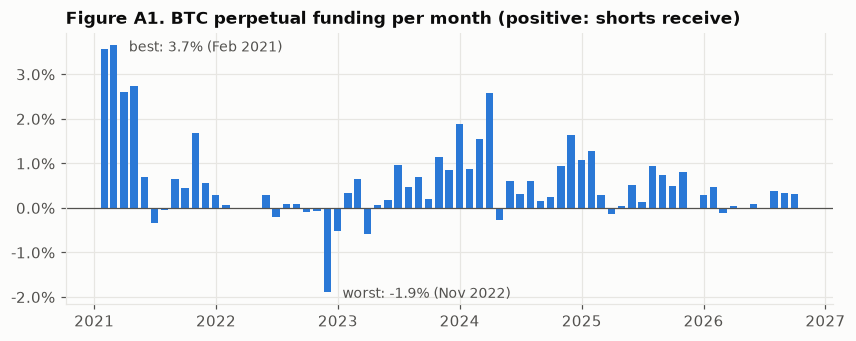

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(monthly.index, monthly.values, width=22, color=BLUE)
ax.axhline(0, color=MUTED, lw=0.8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title("Figure A1. BTC perpetual funding per month (positive: shorts receive)")
for when, label in [(monthly.idxmax(), "best"), (monthly.idxmin(), "worst")]:
    ax.annotate(f"{label}: {monthly[when]:.1%} ({when:%b %Y})", (when, monthly[when]), textcoords="offset points",
                xytext=(10, -4), fontsize=9, color=MUTED)
save(fig, "A1_monthly_funding")
plt.show()

In [6]:
def hedge_pnl(P1, P0=DEMO_P0, D=DEMO_MARGIN, D_counterparty=DEMO_MARGIN, funding_rate=typical_f, days=HOLD_DAYS, with_liquidation=True):
    """A fund owns 1 BTC bought at P0 and is short 1 BTC of perp, with D of sBILL as margin. The counterparty posts tUSDC."""
    P_s, P_l = liq_short(P0, D, 1 - HC_WEEKDAY), liq_long(P0, D_counterparty)
    exit_price, reward = P1, 0.0
    if with_liquidation and P1 >= P_s:
        exit_price, reward = P_s, LIQ_REWARD * P_s   # the fund is liquidated and pays the reward
    elif with_liquidation and P1 <= P_l:
        exit_price = P_l                             # the counterparty is liquidated: the hedge ends, the long pays the reward
    spot = P1 - P0
    perp = (P0 - exit_price) - reward
    fund = funding_rate * (P0 + exit_price) / 2      # paid on the average notional
    loss = max(0.0, exit_price - P0)
    interest = (D - loss / 2) * SBILL_APY * days / 365  # sBILL is sold off as losses are paid
    vault_cost = DISCOUNT * loss * CLOSURE_H / 168   # the share of losses that fall in a closure pay the discount
    return dict(spot=spot, perp=perp, funding=fund, interest=interest, vault_cost=-vault_cost,
                hedged=spot + perp + fund + interest - vault_cost)

moves = np.round(np.arange(-0.5, 0.501, 0.1), 1) + 0.0
scenario = pd.DataFrame({
    "BTC price": DEMO_P0 * (1 + moves),
    "unhedged": [hedge_pnl(DEMO_P0 * (1 + m))["spot"] for m in moves],
    "hedged, no liquidation": [hedge_pnl(DEMO_P0 * (1 + m), with_liquidation=False)["hedged"] for m in moves],
    "hedged, contract rules": [hedge_pnl(DEMO_P0 * (1 + m))["hedged"] for m in moves],
    "same, worst funding month": [hedge_pnl(DEMO_P0 * (1 + m), funding_rate=stressed_f)["hedged"] for m in moves],
}, index=[f"{m:+.0%}" if m else "0%" for m in moves])
scenario.index.name = "BTC move"
P_s, P_l = liq_short(DEMO_P0, DEMO_MARGIN, 1 - HC_WEEKDAY), liq_long(DEMO_P0, DEMO_MARGIN)
print(f"Fund's short is liquidated at ${P_s:,.0f} ({P_s / DEMO_P0 - 1:+.1%}). Counterparty's long is liquidated at ${P_l:,.0f} ({P_l / DEMO_P0 - 1:+.1%}).")
print("Parts of the flat hedged result at +10%:", {k: round(v, 2) for k, v in hedge_pnl(DEMO_P0 * 1.1).items()})
round_trip = hedge_pnl(P_s)["perp"]
print(f"If BTC reaches ${P_s:,.0f}, the hedge is liquidated, and BTC then returns to ${DEMO_P0:,.0f}, the fund is down ${-round_trip:,.0f} on the perp with nothing back on the spot.")
show(scenario, **{c: "${:,.0f}" for c in scenario.columns})

Fund's short is liquidated at $97,959 (+25.8%). Counterparty's long is liquidated at $53,171 (-31.7%).
Parts of the flat hedged result at +10%: {'spot': 7785.37, 'perp': -7785.37, 'funding': np.float64(260.93), 'interest': 85.83, 'vault_cost': -3.01, 'hedged': np.float64(343.75)}
If BTC reaches $97,959, the hedge is liquidated, and BTC then returns to $77,854, the fund is down $20,595 on the perp with nothing back on the spot.


,BTC price,unhedged,"hedged, no liquidation","hedged, contract rules","same, worst funding month"
BTC move,,,,,
-50%,"$38,927","$-38,927",$285,"$-13,936","$-15,377"
-40%,"$46,712","$-31,141",$297,"$-6,151","$-7,592"
-30%,"$54,498","$-23,356",$310,$310,"$-1,146"
-20%,"$62,283","$-15,571",$322,$322,"$-1,219"
-10%,"$70,068","$-7,785",$335,$335,"$-1,292"
0%,"$77,854",$0,$347,$347,"$-1,366"
+10%,"$85,639","$7,785",$344,$344,"$-1,455"
+20%,"$93,424","$15,571",$340,$340,"$-1,544"
+30%,"$101,210","$23,356",$337,"$3,100","$1,166"


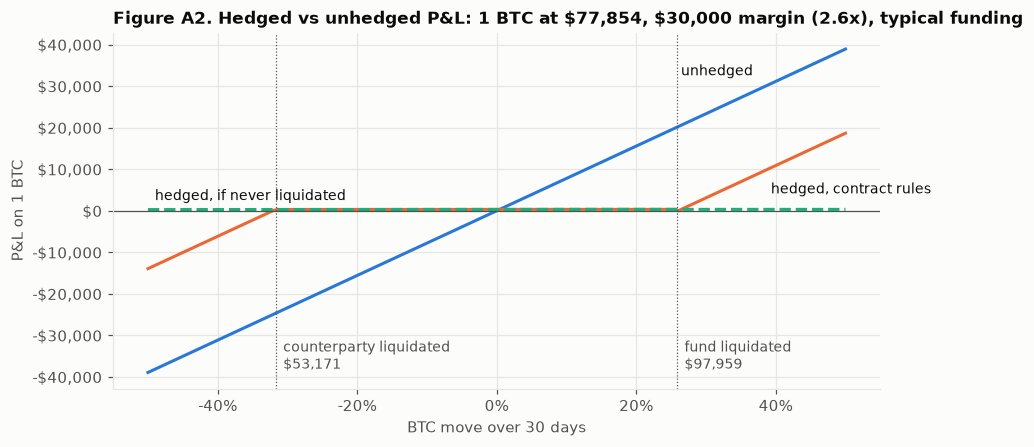

In [7]:
grid = np.linspace(-0.5, 0.5, 201)
fig, ax = plt.subplots(figsize=(9, 4.2))
prices = DEMO_P0 * (1 + grid)
ax.plot(grid, [hedge_pnl(p)["spot"] for p in prices], color=BLUE)
ax.plot(grid, [hedge_pnl(p)["hedged"] for p in prices], color=ORANGE)
ax.plot(grid, [hedge_pnl(p, with_liquidation=False)["hedged"] for p in prices], color=AQUA, ls="--")
ax.axhline(0, color=MUTED, lw=0.8)
for p, text in [(P_s, f"fund liquidated\n${P_s:,.0f}"), (P_l, f"counterparty liquidated\n${P_l:,.0f}")]:
    x = p / DEMO_P0 - 1
    ax.axvline(x, color=MUTED, lw=0.8, ls=":")
    ax.annotate(text, (x, -38_000), xytext=(5, 0), textcoords="offset points", fontsize=9, color=MUTED)
ax.annotate("unhedged", (0.40, hedge_pnl(DEMO_P0 * 1.40)["spot"]), xytext=(-62, 4), textcoords="offset points", fontsize=9)
ax.annotate("hedged, contract rules", (0.38, hedge_pnl(DEMO_P0 * 1.38)["hedged"]), xytext=(6, -14), textcoords="offset points", fontsize=9)
ax.annotate("hedged, if never liquidated", (-0.49, 0), xytext=(0, 7), textcoords="offset points", fontsize=9)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(usd)
ax.set_xlabel("BTC move over 30 days")
ax.set_ylabel("P&L on 1 BTC")
ax.set_title(f"Figure A2. Hedged vs unhedged P&L: 1 BTC at ${DEMO_P0:,.0f}, ${DEMO_MARGIN:,} margin ({DEMO_LEV:.1f}x), typical funding")
save(fig, "A2_hedged_vs_unhedged")
plt.show()

In [8]:
def hedge_backtest(lev, horizon=HOLD_DAYS * 24, step=24):
    """Rolling windows over the real price and funding history. No margin top-ups, and no new hedge after a liquidation."""
    rows = []
    for i in range(0, len(P) - horizon - 1, step):
        P0, P_T = P[i], P[i + horizon]
        D = P0 / lev
        P_short, P_long = liq_short(P0, D, 1 - HC_WEEKDAY), liq_long(P0, D)
        over, under = H[i:i + horizon] >= P_short, L[i:i + horizon] <= P_long
        hit_s = over.argmax() if over.any() else horizon
        hit_l = under.argmax() if under.any() else horizon
        tau = min(hit_s, hit_l)
        if tau == horizon:
            exit_price, reward, status = P_T, 0.0, "none"
        elif hit_s <= hit_l:
            exit_price, reward, status = P_short, LIQ_REWARD * P_short, "fund"
        else:
            exit_price, reward, status = P_long, 0.0, "counterparty"
        fund = (R[i:i + tau] * P[i:i + tau]).sum()
        loss = max(0.0, exit_price - P0)
        interest = (D - loss / 2) * SBILL_APY * horizon / 8760
        hedged = (P_T - P0) + (P0 - exit_price) - reward + fund + interest - DISCOUNT * loss * CLOSURE_H / 168
        rows.append(dict(start=px.index[i], unhedged=(P_T - P0) / P0, hedged=hedged / P0, status=status, funding=fund / P0))
    return pd.DataFrame(rows).set_index("start")

leverages = {"2x": 2.0, f"{DEMO_LEV:.1f}x (demo)": DEMO_LEV, "4x": 4.0, "4.9x (near the limit)": 4.9}
backtests = {name: hedge_backtest(lev) for name, lev in leverages.items()}
rows = {}
for name, b in backtests.items():
    rows[name] = {
        "fund liquidated": (b.status == "fund").mean(), "counterparty liquidated": (b.status == "counterparty").mean(),
        "mean hedged": b.hedged.mean(), "sd hedged": b.hedged.std(), "worst hedged": b.hedged.min(),
        "hedge effectiveness": 1 - b.hedged.var() / b.unhedged.var(),
    }
any_b = next(iter(backtests.values()))
print(f"{len(any_b):,} rolling {HOLD_DAYS}-day windows. Unhedged: mean {any_b.unhedged.mean():.1%}, sd {any_b.unhedged.std():.1%}, worst {any_b.unhedged.min():.1%}. Mean funding received when never liquidated: {backtests['2x'].query('status == \"none\"').funding.mean():.2%}")
hedge_stats = pd.DataFrame(rows).T
show(hedge_stats, **{"fund liquidated": "{:.1%}", "counterparty liquidated": "{:.1%}", "mean hedged": "{:.2%}", "sd hedged": "{:.1%}", "worst hedged": "{:.1%}", "hedge effectiveness": "{:.0%}"})

2,099 rolling 30-day windows. Unhedged: mean 2.6%, sd 16.9%, worst -43.1%. Mean funding received when never liquidated: 0.47%


,fund liquidated,counterparty liquidated,mean hedged,sd hedged,worst hedged,hedge effectiveness
2x,6.9%,0.9%,0.96%,2.9%,-23.2%,97%
2.6x (demo),14.1%,5.5%,1.50%,4.9%,-25.0%,92%
4x,34.4%,23.7%,2.46%,10.7%,-46.1%,60%
4.9x (near the limit),49.5%,33.0%,1.95%,13.7%,-45.1%,34%


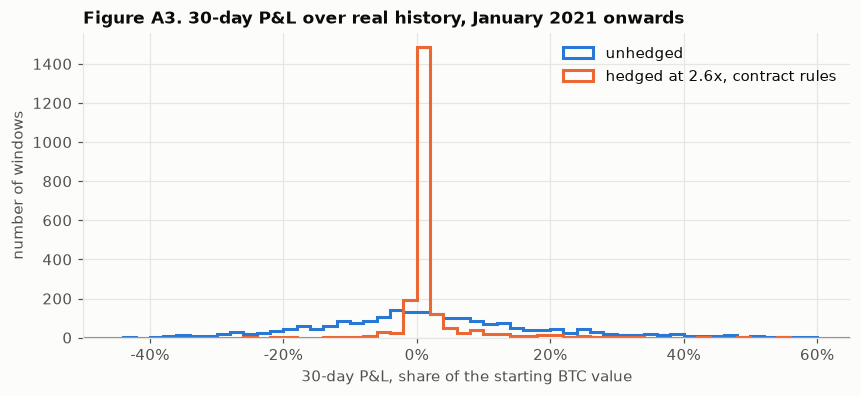

In [9]:
demo_b = backtests[f"{DEMO_LEV:.1f}x (demo)"]
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(-0.6, 0.9, 0.02)
ax.hist(demo_b.unhedged, bins=bins, histtype="step", color=BLUE, lw=2, label="unhedged")
ax.hist(demo_b.hedged, bins=bins, histtype="step", color=ORANGE, lw=2, label=f"hedged at {DEMO_LEV:.1f}x, contract rules")
ax.xaxis.set_major_formatter(pct)
ax.set_xlabel("30-day P&L, share of the starting BTC value")
ax.set_ylabel("number of windows")
ax.legend(loc="upper right")
ax.set_xlim(-0.5, 0.65)
ax.set_title("Figure A3. 30-day P&L over real history, January 2021 onwards")
save(fig, "A3_hedge_backtest")
plt.show()

**Reading the results**

- **Between about -32% and +26% the result is flat**: about \$340 a month on 1 BTC with typical funding, of which about \$260 is funding and \$85 is T-bill interest. The vault's cost is about \$3.
- **Outside that range the fund is unhedged.** Figure A2 looks like a gain on the upside, but it depends on the path. If BTC rises to \$97,959, liquidates the hedge and then falls back, the fund has lost about \$20,600 on the perp with nothing to offset it.
- **The backtest ranks leverage clearly.** Effectiveness (1 - hedged variance / unhedged variance) is 97% at 2x, 92% at 2.6x, 60% at 4x and 34% at 4.9x.
- **Ignore the "mean hedged" column when comparing leverage.** It rises with leverage because BTC went up over the sample, so a fund liquidated out of its short kept that gain. Look at the standard deviation and the worst case.
- **The backtest is pessimistic.** A real fund would add margin or re-hedge after a liquidation. It also assumes the counterparty uses the same leverage.
- **Funding risk is real but small next to price risk.** 20% of months have negative funding, when the short pays. The worst was -1.9% in November 2022. The contract's 0.1% per hour cap was never reached: the largest rate in the data is 0.061% per hour.

## B. Liquidation price

`D` is the deposit and `h` is the share of it that counts as margin (`1 - haircut`, or 1 for tUSDC). `m` is the 10% maintenance margin. After settlement the deposit has paid the loss, and an account is liquidated when what remains, after the haircut, falls below `m` times the notional:

```text
Short: h (D - (P - P0)) = m P   so   P_liq = h (D + P0) / (m + h)
Long:  h (D - (P0 - P)) = m P   so   P_liq = h (P0 - D) / (h - m)
```

This ignores funding, interest and the vault discount. The cell below measures the discount's effect.

In [10]:
print("Check against the guide's example: D = 30,000, P0 = 83,000, h = 0.99 gives", f"${liq_short(83_000, 30_000, 0.99):,.0f}")
collateral = {"tUSDC": 1.0, "sBILL, weekday": 1 - HC_WEEKDAY, "sBILL, weekend": 1 - HC_WEEKEND}
levels = {"2x": 2.0, f"{DEMO_LEV:.1f}x (demo)": DEMO_LEV, "4x": 4.0, "5x": 5.0, "10x": 10.0}
rows = []
for lev_name, lev in levels.items():
    for c_name, h in collateral.items():
        D = DEMO_P0 / lev
        s, l = liq_short(DEMO_P0, D, h), liq_long(DEMO_P0, D, h)
        rows.append({"leverage": lev_name, "margin": c_name, "deposit": D, "can open?": "yes" if h * D >= IM * DEMO_P0 * (1 - 1e-12) else "no",
                     "short liquidated at": s, "short move": round(s / DEMO_P0 - 1, 6) + 0.0, "long liquidated at": l, "long move": round(l / DEMO_P0 - 1, 6) + 0.0})
liq_table = pd.DataFrame(rows).set_index(["leverage", "margin"])
print(f"The most leverage that can open: tUSDC {1 / IM:.2f}x, sBILL weekday {(1 - HC_WEEKDAY) / IM:.2f}x, sBILL weekend {(1 - HC_WEEKEND) / IM:.2f}x")
show(liq_table, **{"deposit": "${:,.0f}", "short liquidated at": "${:,.0f}", "short move": "{:+.1%}", "long liquidated at": "${:,.0f}", "long move": "{:+.1%}"})

Check against the guide's example: D = 30,000, P0 = 83,000, h = 0.99 gives $102,633
The most leverage that can open: tUSDC 5.00x, sBILL weekday 4.95x, sBILL weekend 4.85x


In [11]:
# The formula ignores the vault discount. How much does that matter? With the vault paying the loss, each $1 of loss costs 1/(1-d) of sBILL.
def liq_short_with_discount(P0, D, h, d=DISCOUNT, m=MM):
    return h * (D + P0 / (1 - d)) / (m + h / (1 - d))
exact = liq_short_with_discount(DEMO_P0, DEMO_MARGIN, 1 - HC_WEEKEND)
simple = liq_short(DEMO_P0, DEMO_MARGIN, 1 - HC_WEEKEND)
print(f"Weekend short at the demo size: formula ${simple:,.2f}, with the discount ${exact:,.2f}, difference ${simple - exact:,.2f}")

# How long until a position at each leverage would be liquidated, if the fund adds nothing?
def chance_of_liquidation(lev, hours, step=24):
    rows = np.arange(0, len(P) - hours - 1, step)
    short_hits, long_hits = 0, 0
    for i in rows:
        D = P[i] / lev
        short_hits += H[i:i + hours].max() >= liq_short(P[i], D, 1 - HC_WEEKDAY)
        long_hits += L[i:i + hours].min() <= liq_long(P[i], D)
    return short_hits / len(rows), long_hits / len(rows)

rows = {}
for name, lev in {"2x": 2.0, f"{DEMO_LEV:.1f}x (demo)": DEMO_LEV, "4x": 4.0, "4.9x": 4.9}.items():
    rows[name] = {}
    for label, hours in {"1 week": 168, "30 days": 720, "90 days": 2160}.items():
        s, l = chance_of_liquidation(lev, hours)
        rows[name][f"short, {label}"] = s
        rows[name][f"long, {label}"] = l
liq_prob = pd.DataFrame(rows).T
show(liq_prob, **{c: "{:.1%}" for c in liq_prob.columns})

Weekend short at the demo size: formula $97,773.88, with the discount $97,755.82, difference $18.06


,"short, 1 week","long, 1 week","short, 30 days","long, 30 days","short, 90 days","long, 90 days"
2x,0.2%,0.0%,6.9%,0.9%,28.9%,7.0%
2.6x (demo),1.5%,0.5%,14.1%,5.5%,38.5%,17.8%
4x,9.6%,5.4%,35.9%,24.4%,59.3%,49.5%
4.9x,19.8%,12.8%,55.0%,38.6%,73.2%,63.4%


**Reading the results**

- **Our chosen leverage is the demo's 2.6x**: short liquidated at \$97,959 (+25.8%), long at \$53,171 (-31.7%).
- **5x is the most that can open, and only with tUSDC.** sBILL's haircut lowers the limit to 4.95x on weekdays and 4.85x at weekends. **10x cannot open** under the 20% initial margin, and would be at the liquidation price from the start. It appears only as a comparison.
- **The weekend haircut barely moves the liquidation price**: about \$185 at the demo size.
- **The vault discount can be ignored**: \$18 at the demo size.
- **The leverage limit is about right for trading, but too high for a month-long hedge.** With no top-ups, a position at 4.9x has about a 20% chance of liquidation within a week, and about 55% within 30 days. A hedger should stay near 2x to 2.6x, or plan to add margin.

## C. Weekend vs weekday risk

Is Bitcoin riskier over a weekend, and do the margins hold up?

- **Weekend closure**: Friday 4pm ET to Monday 9am ET, 65 hours.
- **Same length on weekdays**: Monday 4pm ET to Thursday 9am ET, to compare like with like.
- **Weekday overnight**: Monday-Thursday 4pm ET to 9am ET the next day, 17 hours.

VaR is the 99th percentile move, shown for each direction because a short loses when BTC rises and a long loses when it falls. ES (expected shortfall) is the average of the moves beyond the VaR.

In [12]:
def starts(days, hour, tz="America/New_York"):
    t = px.index.tz_convert(tz)
    return np.where(t.day_of_week.isin(days) & (t.hour == hour))[0]

def moves_over(start_idx, hours):
    start_idx = start_idx[start_idx + hours < len(P)]
    return pd.Series(P[start_idx + hours] / P[start_idx] - 1, index=px.index[start_idx])

def risk_row(x, hours):
    up, down = np.quantile(x, 0.99), np.quantile(x, 0.01)
    return {"hours": hours, "windows": len(x), "sd": x.std(), "sd per sqrt hour": x.std() / np.sqrt(hours),
            "99% VaR, price up (short loses)": up, "ES, price up": x[x >= up].mean(), "worst up": x.max(),
            "99% VaR, price down (long loses)": -down, "ES, price down": -x[x <= down].mean(), "worst down": -x.min()}

closure = moves_over(starts([4], 16), CLOSURE_H)                       # Friday 4pm ET, 65 hours
overnight = moves_over(starts([0, 1, 2, 3], 16), OVERNIGHT_H)          # Mon-Thu 4pm ET, 17 hours
weekday_65 = moves_over(starts([0], 16), CLOSURE_H)                    # Monday 4pm ET to Thursday 9am ET: same length, no weekend
contract_wk = moves_over(starts([5], 0, "UTC"), 48)                    # the contract's own weekend
risk = pd.DataFrame({
    "weekend closure (Fri 4pm to Mon 9am ET)": risk_row(closure, CLOSURE_H),
    "contract weekend (Sat-Sun UTC)": risk_row(contract_wk, 48),
    "weekday, same length (Mon 4pm to Thu 9am ET)": risk_row(weekday_65, CLOSURE_H),
    "weekday overnight (Mon-Thu, 4pm to 9am ET)": risk_row(overnight, OVERNIGHT_H),
}).T

rng = np.random.default_rng(6931)
boot = rng.choice(closure.values, size=(5000, len(closure)), replace=True)
ci_up = np.quantile(np.quantile(boot, 0.99, axis=1), [0.05, 0.95])
ci_down = -np.quantile(np.quantile(boot, 0.01, axis=1), [0.95, 0.05])
print(f"Sample: {len(closure)} weekends, so a 99% VaR rests on about {len(closure) // 100} observations.")
print(f"Bootstrap 90% interval for the weekend VaR: price up {ci_up[0]:.1%} to {ci_up[1]:.1%}; price down {ci_down[0]:.1%} to {ci_down[1]:.1%}")
in_closure = pd.Series(False, index=px.index)
for i in starts([4], 16):
    in_closure.iloc[i:i + CLOSURE_H] = True
hourly = px.pct_change().dropna()
print(f"Hourly volatility: inside closures {hourly[in_closure.reindex(hourly.index)].std():.3%}; outside closures {hourly[~in_closure.reindex(hourly.index)].std():.3%}")
show(risk, **{"hours": "{:.0f}", "windows": "{:.0f}", **{c: "{:.2%}" for c in risk.columns if c not in ("hours", "windows")}})

Sample: 304 weekends, so a 99% VaR rests on about 3 observations.
Bootstrap 90% interval for the weekend VaR: price up 7.7% to 13.9%; price down 8.7% to 18.3%
Hourly volatility: inside closures 0.523%; outside closures 0.680%


,hours,windows,sd,sd per sqrt hour,"99% VaR, price up (short loses)","ES, price up",worst up,"99% VaR, price down (long loses)","ES, price down",worst down
weekend closure (Fri 4pm to Mon 9am ET),65,304,4.08%,0.51%,11.10%,14.48%,19.88%,12.97%,17.03%,20.41%
contract weekend (Sat-Sun UTC),48,304,2.76%,0.40%,9.73%,10.99%,12.48%,7.71%,8.33%,8.62%
"weekday, same length (Mon 4pm to Thu 9am ET)",65,304,4.69%,0.58%,12.90%,16.91%,22.30%,10.59%,11.97%,15.63%
"weekday overnight (Mon-Thu, 4pm to 9am ET)",17,1215,2.46%,0.60%,6.70%,8.93%,17.91%,6.62%,8.81%,20.02%


In [13]:
horizons = [1, 2, 4, 8, 12, 24, 48, 65, 168]
log_p = np.log(P)
scale_rows = []
for h in horizons:
    ret = np.exp(log_p[h:] - log_p[:-h]) - 1
    scale_rows.append({"hours": h, "sd": ret.std(), "99% move": np.quantile(np.abs(ret), 0.99), "worst move": np.abs(ret).max(),
                       "share over 10%": (np.abs(ret) > 0.10).mean(), "share over 20%": (np.abs(ret) > 0.20).mean()})
scale = pd.DataFrame(scale_rows).set_index("hours")
scale["sd by sqrt-of-time"] = scale["sd"].iloc[0] * np.sqrt(scale.index)
scale["99% by sqrt-of-time"] = scale["99% move"].iloc[0] * np.sqrt(scale.index)
slope = np.polyfit(np.log(scale.index), np.log(scale["sd"]), 1)[0]
print(f"Fitted growth of the standard deviation with the horizon: exponent {slope:.3f} (the square-root rule says 0.5)")
print(f"Weekend vs overnight sd ratio: {closure.std() / overnight.std():.2f}. Square-root rule: {np.sqrt(CLOSURE_H / OVERNIGHT_H):.2f}")
for h in (1, 2):
    big = pd.Series(np.abs(P[h:] / P[:-h] - 1), index=px.index[h:])
    big = big[big > MM]
    print(f"{h}-hour moves above the {MM:.0%} maintenance margin: {len(big)} of {len(P):,} hours, on {big.index.normalize().nunique()} days ({', '.join(sorted({f'{d:%b %Y}' for d in big.index}))})")
show(scale, **{c: "{:.2%}" for c in scale.columns})

Fitted growth of the standard deviation with the horizon: exponent 0.493 (the square-root rule says 0.5)
Weekend vs overnight sd ratio: 1.66. Square-root rule: 1.96
1-hour moves above the 10% maintenance margin: 2 of 51,083 hours, on 2 days (Jan 2021, May 2021)
2-hour moves above the 10% maintenance margin: 4 of 51,083 hours, on 3 days (Jan 2021, May 2021)


,sd,99% move,worst move,share over 10%,share over 20%,sd by sqrt-of-time,99% by sqrt-of-time
hours,,,,,,,
1,0.62%,2.39%,12.44%,0.00%,0.00%,0.62%,2.39%
2,0.88%,3.33%,14.43%,0.01%,0.00%,0.88%,3.38%
4,1.23%,4.59%,17.29%,0.04%,0.00%,1.25%,4.78%
8,1.72%,6.30%,16.49%,0.13%,0.00%,1.76%,6.75%
12,2.10%,7.63%,18.77%,0.29%,0.00%,2.16%,8.27%
24,2.99%,10.38%,23.42%,1.18%,0.03%,3.06%,11.70%
48,4.15%,13.80%,27.06%,3.31%,0.13%,4.32%,16.54%
65,4.82%,15.89%,30.34%,5.31%,0.35%,5.03%,19.25%
168,7.86%,25.86%,41.20%,16.58%,3.21%,8.08%,30.95%


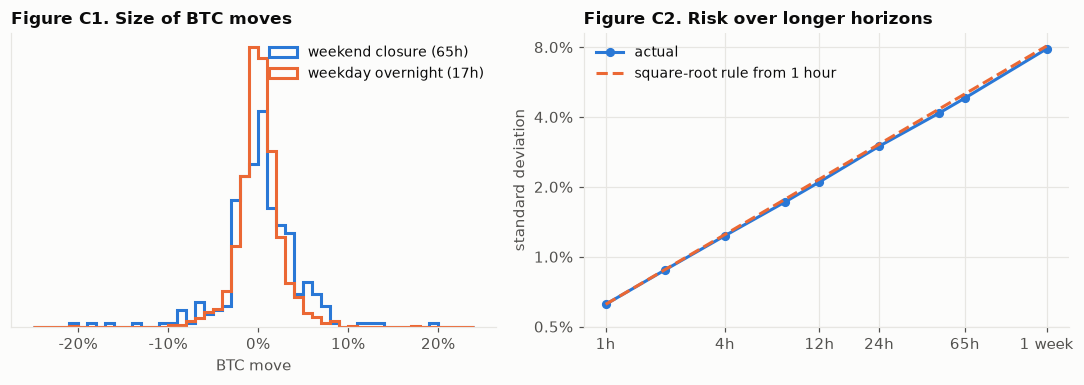

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
bins = np.arange(-0.25, 0.25, 0.01)
ax.hist(closure, bins=bins, histtype="step", density=True, color=BLUE, lw=2, label=f"weekend closure ({CLOSURE_H}h)")
ax.hist(overnight, bins=bins, histtype="step", density=True, color=ORANGE, lw=2, label=f"weekday overnight ({OVERNIGHT_H}h)")
ax.xaxis.set_major_formatter(pct)
ax.set_xlabel("BTC move")
ax.set_yticks([])
ax.grid(False)
ax.legend(loc="upper right", fontsize=9)
ax.set_title("Figure C1. Size of BTC moves")
ax = axes[1]
ax.plot(scale.index, scale["sd"], color=BLUE, marker="o", ms=5, label="actual")
ax.plot(scale.index, scale["sd by sqrt-of-time"], color=ORANGE, ls="--", label="square-root rule from 1 hour")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1, 4, 12, 24, 65, 168], labels=["1h", "4h", "12h", "24h", "65h", "1 week"])
ax.set_yticks([0.005, 0.01, 0.02, 0.04, 0.08])
ax.minorticks_off()
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_ylabel("standard deviation")
ax.legend(fontsize=9)
ax.set_title("Figure C2. Risk over longer horizons")
fig.tight_layout()
save(fig, "C_weekend_risk")
plt.show()

**Reading the results**

- **Per hour, weekends are calmer.** Standard deviation per root hour is 0.51% for closures, against 0.58-0.60% on weekdays. A 65-hour weekday window is at least as risky as a weekend. The weekend problem is that the T-bill market is shut, not that Bitcoin moves more.
- **The square-root rule fits the standard deviation well** (fitted exponent 0.49, the rule says 0.50). It overstates the tails at long horizons: the 99% move over 65 hours is 15.9%, against 19.3% from the rule. A closure is less risky than the rule predicts from weekday overnights (ratio 1.66 against 1.96).
- **Maintenance margin holds up.** A 10% margin would have been breached by a 1-hour move in only 2 of 51,083 hours, and by a 2-hour move in 4, all in January and May 2021. Two hours matters because it is the oldest price the contract accepts. In those rare cases, an account sitting right at maintenance could underpay the winner, as there is no insurance fund.
- **Initial margin is less comfortable for a long hold.** 5.3% of all 65-hour windows moved by more than 10%, which is the gap between initial and maintenance margin, and 0.35% moved by more than 20%.
- **The 3% weekend haircut is far above T-bill price risk**, which Section D puts at 4.5bp (and 8.7bp in the worst case seen). It is conservative but cheap, as Section B shows, so we suggest keeping it and saying why: it also protects against a delayed redemption.
- **The sample is small.** With 304 weekends, the 99% VaR rests on about 3 observations. The 90% bootstrap interval is 7.7-13.9% for rises and 8.7-18.3% for falls, so these should be read as ranges.

## D. Vault economics

This is the question in the professor's feedback: what discount does the vault need, given the T-bill yield and weekend price risk? The answer has two parts, and they give very different numbers.

**Part 1: the cost of each use.** For the cash the vault actually spends in a weekend:

```text
Required discount = net carry + T-bill price risk + redemption risk

gross carry       = hurdle rate x 65 / 8760
net carry         = gross carry - T-bill yield x 65 / 8760   (sBILL keeps earning while the vault holds it)
T-bill price risk = duration x weekend yield shock
redemption risk   = chance of a long weekend x one more day of carry + chance of a gate x loss
```

**Inputs.** The yield shock is measured from `DTB3`, as the change from each Friday to the next published rate. Duration is 3 months, or 1 month in the low case. For redemption risk we assume 9 long weekends a year, a redemption gate once in 20 years (1 in 1,040 weekends) and a 3% loss if it happens. For scale, the Reserve Primary Fund fell to \$0.97 in 2008, though it held commercial paper, not only T-bills. The gate figures are our judgement.

**Part 2: the cost of cash that waits.** The vault must hold enough cash for a bad weekend, but most weekends use little of it. Each weekend's use comes from the real price path:

```text
sBILL sold in a weekend = largest loss reached from Friday's price, at any hourly settlement
```

This is the largest loss, not the final loss, because a fund pays from any cash it won earlier in the weekend and sells sBILL only for the rest. Then, with `u` the average share of cash used:

```text
Vault return    = 52 x u x (discount + T-bill yield x 65 / 8760)
With a sweep    = the above + T-bill yield x 103 / 168
```

A "sweep" means holding idle cash in T-bills on business days. The contracts do not do this today. It is an extension for a real product.

In [15]:
# How much does the 3-month T-bill yield move over a weekend? Friday's rate to the next published rate.
fridays = tbill[tbill.index.day_of_week == 4]
next_rate = tbill.shift(-1).reindex(fridays.index)
next_date = pd.Series(tbill.index, index=tbill.index).shift(-1).reindex(fridays.index)
weekend_shift = (next_rate - fridays)[(next_date - fridays.index).dt.days <= 4].dropna()
shock_abs = weekend_shift.abs()
shock95, shock99, shock_max = shock_abs.quantile(.95), shock_abs.quantile(.99), shock_abs.max()
print(f"{len(weekend_shift)} weekends since {weekend_shift.index[0]:%Y}. |yield move|: median {shock_abs.median() * 1e4:.0f}bp, 95th {shock95 * 1e4:.0f}bp, 99th {shock99 * 1e4:.0f}bp, largest {shock_max * 1e4:.0f}bp")
print("Largest moves:", ", ".join(f"{d:%Y-%m-%d} {v * 1e4:+.0f}bp" for d, v in weekend_shift.reindex(shock_abs.sort_values().index[-4:][::-1]).items()))

INVESTOR = assume["vaultInvestor"]
P_LONG_WEEKEND = INVESTOR["longWeekendsPerYear"] / WEEKENDS
P_GATE = 1 / (INVESTOR["fundGatesOncePerYears"] * WEEKENDS)

def required_discount(y, hurdle, hours, duration, shock, p_long_weekend=P_LONG_WEEKEND, extra_h=INVESTOR["longWeekendExtraHours"], p_gate=P_GATE, gate_loss=INVESTOR["gateLoss"]):
    """Discount per weekend the vault needs on the cash it actually uses."""
    gross_carry = hurdle * hours / 8760
    accrual = y * hours / 8760  # sBILL keeps earning while the vault holds it
    return {"gross carry": gross_carry, "less sBILL accrual": -accrual, "net carry": gross_carry - accrual,
            "T-bill price risk": duration * shock,
            "redemption risk": p_long_weekend * hurdle * extra_h / 8760 + p_gate * gate_loss}

cases = {name: dict(hurdle=y_now + c["hurdlePremium"], duration=c["tBillDurationYears"], shock=shock_abs.quantile(c["yieldShockPercentile"]))
         for name, c in INVESTOR["cases"].items()}
d_table = pd.DataFrame({k: required_discount(y_now, hours=CLOSURE_H, **v) for k, v in cases.items()}).T
d_table["required discount"] = d_table["net carry"] + d_table["T-bill price risk"] + d_table["redemption risk"]
print(f"Discount in the contract: {DISCOUNT * 1e4:.0f}bp")
show(d_table * 1e4, **{c: "{:.1f}bp" for c in d_table.columns})

597 weekends since 2015. |yield move|: median 2bp, 95th 10bp, 99th 18bp, largest 35bp
Largest moves: 2022-06-10 +35bp, 2023-03-17 +29bp, 2022-07-08 +22bp, 2022-10-07 +22bp
Discount in the contract: 10bp


,gross carry,less sBILL accrual,net carry,T-bill price risk,redemption risk,required discount
low,3.0bp,-3.0bp,0.0bp,0.8bp,0.5bp,1.3bp
base,4.5bp,-3.0bp,1.5bp,4.5bp,0.6bp,6.6bp
stress,6.7bp,-3.0bp,3.7bp,8.7bp,0.7bp,13.2bp


In [16]:
# Sensitivity: required discount (bp) when the inputs move.
durations = [1 / 12, 1 / 6, 0.25, 0.5]
shocks = [0.0005, 0.001, 0.002, 0.004, 0.008]
sens = pd.DataFrame(
    [[sum(required_discount(y_now, y_now + HURDLE_PREMIUM, CLOSURE_H, dur, s)[k] for k in ("net carry", "T-bill price risk", "redemption risk")) * 1e4
      for s in shocks] for dur in durations],
    index=[f"duration {dur * 12:.0f} months" for dur in durations], columns=[f"{s * 1e4:.0f}bp shock" for s in shocks])
display(show(sens, **{c: "{:.1f}" for c in sens.columns}))
sens_y = pd.DataFrame(
    {f"T-bills at {y:.0%}": {f"premium {p:.0%}": sum(required_discount(y, y + p, CLOSURE_H, 0.25, shock99)[k] for k in ("net carry", "T-bill price risk", "redemption risk")) * 1e4
                             for p in (0.0, 0.02, 0.05, 0.10)} for y in (0.0, 0.02, 0.04, 0.06)})
show(sens_y, **{c: "{:.1f}" for c in sens_y.columns})

,5bp shock,10bp shock,20bp shock,40bp shock,80bp shock
duration 1 months,2.5,2.9,3.7,5.4,8.7
duration 2 months,2.9,3.7,5.4,8.7,15.4
duration 3 months,3.3,4.6,7.1,12.1,22.1
duration 6 months,4.6,7.1,12.1,22.1,42.1


,T-bills at 0%,T-bills at 2%,T-bills at 4%,T-bills at 6%
premium 0%,4.8,4.9,5.0,5.1
premium 2%,6.4,6.5,6.6,6.7
premium 5%,8.7,8.8,8.9,9.0
premium 10%,12.7,12.8,12.9,13.0


In [17]:
# Vault use each real weekend. With hourly settlement a fund pays from cash it won earlier, and sells sBILL only for the rest.
# So sBILL sold over a weekend = the largest loss reached from Friday's price at any settlement.
rows = []
for i in starts([4], 16):
    if i + CLOSURE_H >= len(P):
        continue
    path = P[i:i + CLOSURE_H + 1]
    rows.append(dict(start=px.index[i], p0=P[i], short_sold=max(0.0, path.max() / P[i] - 1), long_sold=max(0.0, 1 - path.min() / P[i]), final=path[-1] / P[i] - 1))
weekends = pd.DataFrame(rows).set_index("start")
weekends["year"] = weekends.index.year
S = weekends["short_sold"]
print(f"A hedging fund (short, all sBILL) sells on average {S.mean():.2%} of notional a weekend; median {S.median():.2%}; largest {S.max():.1%}")

def vault_income(d, u, y):
    """Income on the vault's capital in a year, excluding any return on cash it does not use."""
    return WEEKENDS * u * (d + y * CLOSURE_H / 8760)

def discount_needed(u, y, hurdle, sweep=False):
    """Discount at which the vault earns `hurdle`. With sweep, idle cash earns T-bills on business days."""
    idle = y * (168 - CLOSURE_H) / 168 if sweep else 0.0
    return (hurdle - idle) / (WEEKENDS * u) - y * CLOSURE_H / 8760

L_ = weekends["long_sold"]
both = S + L_  # per $1 of sBILL-backed shorts and $1 of sBILL-backed longs: only the losing side sells at any moment
x_short, x_long, x_both = S.quantile(0.99), L_.quantile(0.99), both.quantile(0.99)
print(f"99% of weekends: shorts alone need {x_short:.1%} of their notional, longs alone {x_long:.1%}, one pool for both {x_both:.1%}. Pooling saves {1 - x_both / (x_short + x_long):.0%} of the cash.")

def vault_row(use, q, name):
    size = use.quantile(q)
    u = (use.clip(upper=size) / size).mean()
    return {"customers": name, "sized for": f"{q:.0%} of weekends" if q < 1 else "worst so far", "cash, share of notional": size, "average use": u, "weekends short": (use > size).mean(),
            "return at 10bp": vault_income(DISCOUNT, u, y_now), "with weekday sweep": vault_income(DISCOUNT, u, y_now) + y_now * (168 - CLOSURE_H) / 168,
            "needs for T-bills": discount_needed(u, y_now, y_now), "needs for T-bills + 2%": discount_needed(u, y_now, y_now + HURDLE_PREMIUM),
            "with sweep, T-bills": discount_needed(u, y_now, y_now, sweep=True), "with sweep, T-bills + 2%": discount_needed(u, y_now, y_now + HURDLE_PREMIUM, sweep=True)}

size_table = pd.DataFrame([vault_row(use, q, name) for name, use in (("shorts only", S), ("both directions", both)) for q in (0.95, 0.99, 1.0)]).set_index(["customers", "sized for"])
u_short = size_table.loc[("shorts only", "99% of weekends"), "average use"]
u_both = size_table.loc[("both directions", "99% of weekends"), "average use"]
x99 = x_short
d_short = size_table.loc[("shorts only", "99% of weekends"), "needs for T-bills + 2%"]
d_both = size_table.loc[("both directions", "99% of weekends"), "needs for T-bills + 2%"]
d_both_tbill = size_table.loc[("both directions", "99% of weekends"), "needs for T-bills"]
print(f"T-bills pay {y_now:.2%}. Per-use discount in the base case: {d_table.loc['base', 'required discount'] * 1e4:.1f}bp. Contract: {DISCOUNT * 1e4:.0f}bp.")
show(size_table, **{"cash, share of notional": "{:.1%}", "average use": "{:.0%}", "weekends short": "{:.1%}", "return at 10bp": "{:.2%}", "with weekday sweep": "{:.2%}",
                    **{c: (lambda v: f"{v * 1e4:.0f}bp") for c in size_table.columns if "T-bills" in c}})

A hedging fund (short, all sBILL) sells on average 2.50% of notional a weekend; median 1.80%; largest 19.9%
99% of weekends: shorts alone need 13.5% of their notional, longs alone 14.4%, one pool for both 19.7%. Pooling saves 29% of the cash.
T-bills pay 4.01%. Per-use discount in the base case: 6.6bp. Contract: 10bp.


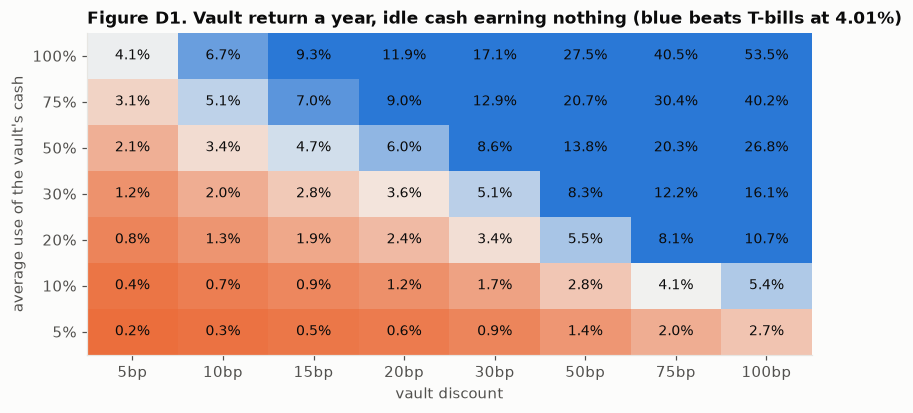

,weekends,weekends of full use,T-bill yield,"vault return, 10bp",vault minus T-bills
year,,,,,
2021,53,16.9,0.05%,1.70%,+1.65%
2022,52,7.8,2.02%,0.89%,-1.13%
2023,52,8.2,5.07%,1.13%,-3.94%
2024,52,8.6,4.97%,1.18%,-3.79%
2025,52,7.7,4.07%,1.00%,-3.06%
2026,43,6.4,3.71%,0.81%,-2.90%


In [18]:
discounts = np.array([5, 10, 15, 20, 30, 50, 75, 100]) * 1e-4
uses = np.array([0.05, 0.10, 0.20, 0.30, 0.50, 0.75, 1.00])
ret = np.array([[vault_income(d, u, y_now) for d in discounts] for u in uses])
excess = ret - y_now
fig, ax = plt.subplots(figsize=(8.5, 3.8))
limit = 0.04  # colours saturate at T-bills +/- 4%
from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("div", [ORANGE, "#f4f3f0", BLUE])
ax.imshow(excess, cmap=diverging, vmin=-limit, vmax=limit, aspect="auto", origin="lower")
ax.set_xticks(range(len(discounts)), [f"{d * 1e4:.0f}bp" for d in discounts])
ax.set_yticks(range(len(uses)), [f"{u:.0%}" for u in uses])
ax.grid(False)
for i in range(len(uses)):
    for j in range(len(discounts)):
        ax.text(j, i, f"{ret[i, j]:.1%}", ha="center", va="center", fontsize=9, color=INK)
ax.set_xlabel("vault discount")
ax.set_ylabel("average use of the vault's cash")
ax.set_title(f"Figure D1. Vault return a year, idle cash earning nothing (blue beats T-bills at {y_now:.2%})")
save(fig, "D1_vault_return")
plt.show()

yearly = weekends.groupby("year").agg(weekends=("short_sold", "size"), sold=("short_sold", "sum"), used=("short_sold", lambda s: (s.clip(upper=x99) / x99).sum()))
yearly["T-bill yield"] = tbill.groupby(tbill.index.year).mean().reindex(yearly.index)
yearly["vault return, 10bp"] = yearly["used"] * (DISCOUNT + yearly["T-bill yield"] * CLOSURE_H / 8760)
yearly["vault minus T-bills"] = yearly["vault return, 10bp"] - yearly["T-bill yield"]
show(yearly[["weekends", "used", "T-bill yield", "vault return, 10bp", "vault minus T-bills"]].rename(columns={"used": "weekends of full use"}),
     **{"weekends of full use": "{:.1f}", "T-bill yield": "{:.2%}", "vault return, 10bp": "{:.2%}", "vault minus T-bills": "{:+.2%}"})

**Reading the results**

- **Part 1: 10bp is enough for each use.** The required discount is 1.3bp in the low case, 6.6bp in the base case and 13.2bp in the stress case. Price risk is the largest part.
- **The level of T-bill yields hardly matters for Part 1**, because the vault earns the T-bill yield while it holds sBILL. What matters is the premium its investors want (about 0.8bp for each extra 1%) and the yield shock.
- **Part 2: 10bp is not enough for the vault as a business.** At 99% sizing, the vault is used 18% on average serving shorts only, and returns 1.23% a year against 4.01% on T-bills. Only 2021 beat T-bills, when they paid almost nothing.
- **What would fix it:**
  - **A higher discount.** With shorts only: 39bp to match T-bills, 60bp for T-bills + 2%.
  - **Serving both directions.** One pool for longs and shorts needs 29% less cash than two separate pools, because only the losing side sells at any moment. The discount then falls to 28bp to match T-bills, 44bp for T-bills + 2%.
  - **A weekday sweep.** Both directions plus a sweep need only 9bp to match T-bills, 25bp for T-bills + 2%.
- **Smaller vaults earn more but fail more often.** At 95% sizing the vault runs out on about 5% of weekends. When that happens `settle()` reverts, so settlement waits until Monday or until more cash arrives. This is a real trade-off, which is why we size at 99%.
- **What this means for the project.** We suggest keeping 10bp in the deployed contracts and reporting this result openly in the report's design decisions: 10bp was our estimate before the analysis, and it covers the risk of each use, but a real vault would need about 30-40bp or a sweep. The discount is fixed at deployment, so changing it would mean deploying the demo again.

## E. Vault vs idle cash

The other side of the trade: is a fund better off using the vault? Take a \$1,000,000 hedge at the demo's leverage, and compare four ways to hold the margin over a year.

```text
1. All cash:                    income = 0
2. T-bills + cash buffer:       income = y x (M - buffer)                  buffer = 99% weekend move x notional
3. T-bills, swapped each Friday: income = y x (M - buffer x 65/168)         must sell and rebuy every week
4. All T-bills + vault:         income = y x M - discount x sBILL sold
```

The break-even discount is where plan 4 equals each of the others. This is the most the fund would pay, and it sets the top of the range. Section D sets the bottom.

The sBILL sold is an upper bound, because it assumes that the fund starts each weekend with no cash. Plan 4 ignores the cost of rebuying sBILL on Monday, which is the only other step needed.

In [19]:
NOTIONAL = assume["fund"]["hedgeNotionalUsd"]
M = NOTIONAL / DEMO_LEV
sold_a_year = WEEKENDS * S.mean() * NOTIONAL
buffer = x99 * NOTIONAL

def net_vault(d, y=y_now):
    return y * M - d * sold_a_year

cash_buffer = y_now * (M - buffer)
weekend_only_buffer = y_now * (M - buffer * CLOSURE_H / 168)
plans = pd.DataFrame({
    "yield on margin": [0.0, cash_buffer, weekend_only_buffer, y_now * M],
    "vault cost": [0.0, 0.0, 0.0, -DISCOUNT * sold_a_year],
}, index=["1. all margin in cash", f"2. T-bills, plus a {x99:.1%} cash buffer all year", "3. T-bills, swapped to the same cash buffer every Friday", "4. all T-bills, vault at 10bp"])
plans["net a year"] = plans.sum(axis=1)
plans["net, % of margin"] = plans["net a year"] / M
limit_cash = y_now * M / sold_a_year
limit_buffer = y_now * buffer / sold_a_year
limit_swap = limit_buffer * CLOSURE_H / 168
print(f"${NOTIONAL:,} hedge with ${M:,.0f} margin ({DEMO_LEV:.1f}x). sBILL sold through the vault: about ${sold_a_year:,.0f} a year, an upper bound because it assumes no cash at the start of each weekend.")
print(f"The fund prefers the vault up to a discount of {limit_swap * 1e4:.0f}bp against plan 3, {limit_buffer * 1e4:.0f}bp against plan 2, and {limit_cash * 1e4:.0f}bp against plan 1.")
print(f"The vault needs {d_short * 1e4:.0f}bp serving shorts only, or {d_both * 1e4:.0f}bp serving both directions, to earn T-bills + {HURDLE_PREMIUM:.0%}, with idle cash earning nothing ({d_both_tbill * 1e4:.0f}bp to match T-bills, both directions).")
show(plans, **{"yield on margin": "${:,.0f}", "vault cost": "${:,.0f}", "net a year": "${:,.0f}", "net, % of margin": "{:.2%}"})

$1,000,000 hedge with $385,338 margin (2.6x). sBILL sold through the vault: about $1,301,320 a year, an upper bound because it assumes no cash at the start of each weekend.
The fund prefers the vault up to a discount of 16bp against plan 3, 42bp against plan 2, and 119bp against plan 1.
The vault needs 60bp serving shorts only, or 44bp serving both directions, to earn T-bills + 2%, with idle cash earning nothing (28bp to match T-bills, both directions).


,yield on margin,vault cost,net a year,"net, % of margin"
1. all margin in cash,$0,$0,$0,0.00%
"2. T-bills, plus a 13.5% cash buffer all year","$10,050",$0,"$10,050",2.61%
"3. T-bills, swapped to the same cash buffer every Friday","$13,362",$0,"$13,362",3.47%
"4. all T-bills, vault at 10bp","$15,452","$-1,301","$14,151",3.67%


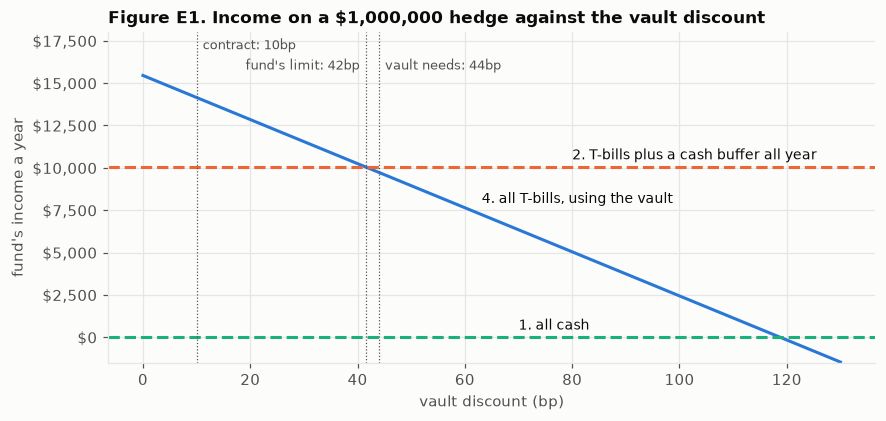

In [20]:
xs = np.linspace(0, 130, 131) * 1e-4
fig, ax = plt.subplots(figsize=(9, 3.9))
ax.plot(xs * 1e4, net_vault(xs), color=BLUE)
ax.axhline(cash_buffer, color=ORANGE, ls="--")
ax.axhline(0, color=AQUA, ls="--")
ax.set_ylim(-1_500, 18_000)
ax.annotate("4. all T-bills, using the vault", (62, net_vault(0.0062)), xytext=(4, 6), textcoords="offset points", fontsize=9)
ax.annotate("2. T-bills plus a cash buffer all year", (80, cash_buffer), xytext=(0, 5), textcoords="offset points", fontsize=9)
ax.annotate("1. all cash", (70, 0), xytext=(0, 5), textcoords="offset points", fontsize=9)
for x, label, side, gap, height in [(DISCOUNT, "contract: 10bp", "left", 4, 17_000), (limit_buffer, f"fund's limit: {limit_buffer * 1e4:.0f}bp", "right", -4, 15_800), (d_both, f"vault needs: {d_both * 1e4:.0f}bp", "left", 4, 15_800)]:
    ax.axvline(x * 1e4, color=MUTED, lw=0.8, ls=":")
    ax.annotate(label, (x * 1e4, height), xytext=(gap, 0), textcoords="offset points", fontsize=8.5, color=MUTED, ha=side)
ax.yaxis.set_major_formatter(usd)
ax.set_xlabel("vault discount (bp)")
ax.set_ylabel("fund's income a year")
ax.set_title(f"Figure E1. Income on a ${NOTIONAL:,} hedge against the vault discount")
save(fig, "E1_fund_income_vs_discount")
plt.show()

In [21]:
yearly_fund = pd.DataFrame({
    "T-bill yield": yearly["T-bill yield"],
    "T-bill income": yearly["T-bill yield"] * M,
    "vault cost at 10bp": -DISCOUNT * yearly["sold"] * NOTIONAL,
})
yearly_fund["net"] = yearly_fund.sum(axis=1) - yearly_fund["T-bill yield"]
show(yearly_fund, **{"T-bill yield": "{:.2%}", "T-bill income": "${:,.0f}", "vault cost at 10bp": "${:,.0f}", "net": "${:,.0f}"})

,T-bill yield,T-bill income,vault cost at 10bp,net
year,,,,
2021,0.05%,$173,"$-2,395","$-2,222"
2022,2.02%,"$7,802","$-1,046","$6,756"
2023,5.07%,"$19,540","$-1,110","$18,430"
2024,4.97%,"$19,151","$-1,164","$17,987"
2025,4.07%,"$15,665","$-1,036","$14,629"
2026,3.71%,"$14,291",$-856,"$13,435"


Friday 4pm ET: $116,673. Lowest hourly price $109,765 (-5.9%), lowest trade $107,000 (-8.3%), Monday 9am ET $114,502
Demo size, 1 BTC with $30,000 margin (3.9x at that price). Long liquidation prices: {'tUSDC': '$96,303', 'sBILL at the weekend': '$96,635'}
An sBILL-backed long would have sold $6,908 to the vault ($9,673 if settled at the lowest trade), 19% of the $50,000 demo vault at most.
Worst weekend in the sample: 20.4%. At today's price that is $15,829 per BTC, so the demo vault covers about 3.2 BTC of sBILL-backed positions on the losing side.


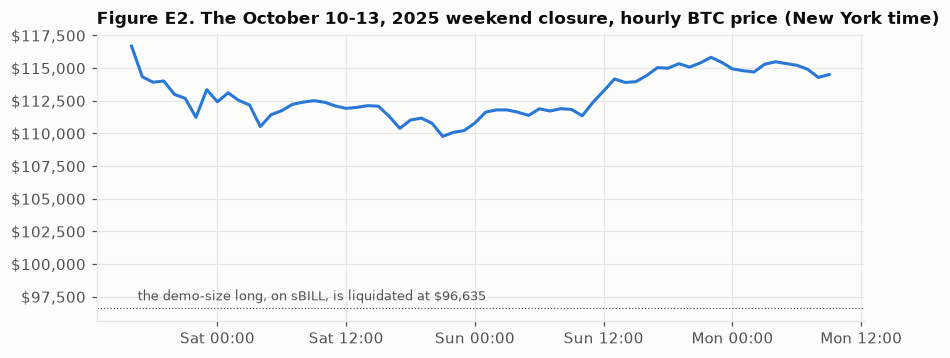

,Friday price,short sells,long sells,Friday to Monday
start,,,,
2024-08-02,"$62,558",0.0%,20.4%,-20.4%
2021-07-23,"$32,268",19.9%,0.0%,+19.9%
2022-06-10,"$28,951",1.4%,18.3%,-18.3%
2021-01-01,"$29,290",17.8%,0.2%,+7.4%
2021-01-08,"$39,073",5.5%,16.5%,-16.3%
2021-02-05,"$37,772",14.5%,0.0%,+13.9%
2021-05-14,"$50,165",1.0%,14.4%,-10.3%
2021-04-16,"$61,853",0.9%,13.7%,-8.5%


In [22]:
# Stress test: October 10-11, 2025. The weekend closure starts Friday October 10, 4pm ET.
t0 = pd.Timestamp("2025-10-10 16:00", tz="America/New_York").tz_convert("UTC")
i0 = px.index.get_loc(t0)
seg = px.iloc[i0:i0 + CLOSURE_H + 1]
p0 = P[i0]
low_settled, low_intra = seg.min(), lo.iloc[i0:i0 + CLOSURE_H].min()
drop, intra = 1 - low_settled / p0, 1 - low_intra / p0
long_liq = {name: liq_long(p0, DEMO_MARGIN, h) for name, h in {"tUSDC": 1.0, "sBILL at the weekend": 1 - HC_WEEKEND}.items()}
print(f"Friday 4pm ET: ${p0:,.0f}. Lowest hourly price ${low_settled:,.0f} ({-drop:.1%}), lowest trade ${low_intra:,.0f} ({-intra:.1%}), Monday 9am ET ${seg.iloc[-1]:,.0f}")
print(f"Demo size, 1 BTC with ${DEMO_MARGIN:,} margin ({p0 / DEMO_MARGIN:.1f}x at that price). Long liquidation prices:", {k: f"${v:,.0f}" for k, v in long_liq.items()})
need, need_intra = p0 * drop, p0 * intra
print(f"An sBILL-backed long would have sold ${need:,.0f} to the vault (${need_intra:,.0f} if settled at the lowest trade), {need_intra / DEMO_VAULT:.0%} of the ${DEMO_VAULT:,} demo vault at most.")
worst_ever = max(S.max(), L_.max())
print(f"Worst weekend in the sample: {worst_ever:.1%}. At today's price that is ${worst_ever * P[-1]:,.0f} per BTC, so the demo vault covers about {DEMO_VAULT / (worst_ever * P[-1]):.1f} BTC of sBILL-backed positions on the losing side.")

top = weekends.assign(worst=weekends[["short_sold", "long_sold"]].max(axis=1)).sort_values("worst", ascending=False).head(8)
top_table = top[["p0", "short_sold", "long_sold", "final"]].copy()
top_table.index = top_table.index.tz_convert("America/New_York").strftime("%Y-%m-%d")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(seg.index.tz_convert("America/New_York").tz_localize(None), seg.values, color=BLUE)
v = long_liq["sBILL at the weekend"]
ax.axhline(v, color=MUTED, lw=0.8, ls=":")
ax.annotate(f"the demo-size long, on sBILL, is liquidated at ${v:,.0f}", (seg.index[0].tz_convert("America/New_York").tz_localize(None), v), xytext=(4, 5), textcoords="offset points", fontsize=8.5, color=MUTED)
from matplotlib.dates import DateFormatter
ax.xaxis.set_major_formatter(DateFormatter("%a %H:%M"))
ax.yaxis.set_major_formatter(usd)
ax.set_title("Figure E2. The October 10-13, 2025 weekend closure, hourly BTC price (New York time)")
save(fig, "E2_oct_2025_stress")
plt.show()
show(top_table.rename(columns={"p0": "Friday price", "short_sold": "short sells", "long_sold": "long sells", "final": "Friday to Monday"}),
     **{"Friday price": "${:,.0f}", "short sells": "{:.1%}", "long sells": "{:.1%}", "Friday to Monday": "{:+.1%}"})

**Reading the results**

- **The fund clearly gains.** At 10bp it earns 3.67% on its margin, against 2.61% with a buffer and nothing in all cash. It pays about \$1,300 a year in discounts to earn about \$15,450 in T-bill interest.
- **A price both sides accept exists, but the room is narrow.** The fund pays up to 42bp compared with a cash buffer. The vault needs 28-44bp serving both directions. Figure E1 shows these two lines almost touching. Without pooling longs and shorts (60bp to earn T-bills + 2%), there is little room at all.
- **A fund that can swap into cash every Friday (plan 3) is a harder competitor.** Its limit is only 16bp, which would need the vault's weekday sweep to compete. In practice those weekly trades cost money and rely on the fund's operations each week, which this comparison leaves out.
- **It needs interest rates.** In 2021, T-bills paid 0.05% and the discounts would have cost more than the interest (-\$2,222). The product is only worth using when rates are well above zero.
- **Stress test, October 10-13, 2025.** On Coinbase, BTC fell only 5.9% on the hourly prices (8.3% at the lowest trade) from the Friday 4pm ET price of \$116,673. Other coins and other venues fell further that weekend, which this BTC-only, one-exchange data does not show. The demo position's long side would have sold \$6,908-\$9,673 to the vault, at most 19% of the \$50,000 demo vault, and would not have been liquidated.
- **The worst weekend in our data was bigger**: -20.4% in August 2024. At today's price that is about \$15,800 per BTC, so the \$50,000 demo vault covers about 3.2 BTC of sBILL-backed positions on the losing side. It is fine for the demo, and shows why vault size has to grow with open interest.

## F. Reconciling with the chain

The brief requires at least one model number to match a deployed contract. This section compares every number it can. Contracts use whole-number maths with 18 decimals, so the model uses Python integers and rounds as the contract does, and a match means **exactly** equal, to the last of 18 decimals.

This section reads the labelled **Demo** deployment, plus the liquidation on the **Stress** set, using the address and ABI files in `packages/hardhat/deployments/`. It needs the internet, and a public RPC is used by default. Set `SEPOLIA_RPC_URL` to use another, and `DEPLOYMENT_NETWORK=default` to read a local chain.

Sai creates the on-chain history with one command, which needs the deployer key: `yarn onchain:all`. Until that has run, this section is skipped.

In [23]:
from IPython.display import display
from web3 import Web3

NETWORK = os.environ.get("DEPLOYMENT_NETWORK", "sepolia")
RPC = os.environ.get("SEPOLIA_RPC_URL", "https://ethereum-sepolia-rpc.publicnode.com")
w3 = Web3(Web3.HTTPProvider(RPC, request_kwargs={"timeout": 30}))
DEPLOYMENTS = ROOT / "packages" / "hardhat" / "deployments" / NETWORK
ETHERSCAN = "https://sepolia.etherscan.io"
ON_CHAIN = (DEPLOYMENTS / "DemoClearinghouse.json").exists()
if not ON_CHAIN:
    print(f"Nothing is deployed on {NETWORK} yet, so this section is skipped. Sections A-E and G do not need it. Run yarn onchain:all first.")

In [24]:
if ON_CHAIN:
    def contract(name, prefix="Demo"):
        d = json.loads((DEPLOYMENTS / f"{prefix}{name}.json").read_text())
        return w3.eth.contract(address=Web3.to_checksum_address(d["address"]), abi=d["abi"]), int(d["receipt"]["blockNumber"], 16)

    (ch, first_block), (vault, _), (sbill, _) = [contract(n) for n in ("Clearinghouse", "WeekendVault", "SBill")]
    block = w3.eth.block_number - 3      # one fixed block, so every read below sees the same state
    ts = w3.eth.get_block(block)["timestamp"]
    at = lambda fn: fn.call(block_identifier=block)
    print(f"Network {NETWORK}, block {block}, {pd.Timestamp(ts, unit='s'):%Y-%m-%d %H:%M} UTC")

    # Do the settings used above match the deployed contracts?
    settings = pd.DataFrame([
        ("initial margin (bps)", IM * 1e4, at(ch.functions.initialMarginBps())),
        ("maintenance margin (bps)", MM * 1e4, at(ch.functions.maintenanceMarginBps())),
        ("weekday haircut (bps)", HC_WEEKDAY * 1e4, at(ch.functions.weekdayHaircutBps())),
        ("weekend haircut (bps)", HC_WEEKEND * 1e4, at(ch.functions.weekendHaircutBps())),
        ("liquidation reward (bps)", LIQ_REWARD * 1e4, at(ch.functions.liquidationRewardBps())),
        ("funding cap per hour (1e18 = 100%)", FUNDING_CAP_H * 1e18, at(ch.functions.maxFundingRatePerHour())),
        ("vault discount (bps)", DISCOUNT * 1e4, at(vault.functions.discountBps())),
        ("sBILL interest (bps)", SBILL_APY * 1e4, at(sbill.functions.apyBps())),
    ], columns=["setting", "in config/protocol.json", "on chain"]).set_index("setting")
    settings["match"] = (settings["in config/protocol.json"] - settings["on chain"]).abs() < 1e-3
    assert settings["match"].all(), "A setting differs from the deployed contract. The contract wins: update config/protocol.json."
    display(show(settings, **{"in config/protocol.json": "{:,.0f}", "on chain": "{:,.0f}"}))

Network sepolia, block 12045137, 2026-11-02 02:18 UTC


,in config/protocol.json,on chain,match
setting,,,
initial margin (bps),"2,000","2,000",True
maintenance margin (bps),"1,000","1,000",True
weekday haircut (bps),100,100,True
weekend haircut (bps),300,300,True
liquidation reward (bps),50,50,True
funding cap per hour (1e18 = 100%),"1,000,000,000,000,000","1,000,000,000,000,000",True
vault discount (bps),10,10,True
sBILL interest (bps),400,400,True


In [25]:
if ON_CHAIN:
    # The contract's maths, in Python integers, rounded the same way. Solidity's signed division rounds toward zero.
    ONE, BPS, YEAR, HOUR = 10**18, 10_000, 365 * 86_400, 3_600

    def tdiv(a, b):
        q = abs(a) // abs(b)
        return q if (a < 0) == (b < 0) else -q

    def ceil_div(a, b):
        return -(-a // b)

    def nav_model(t, start, apy_bps):
        return ONE + ONE * apy_bps * (t - start) // (BPS * YEAR)

    def vault_price_model(nav, discount_bps):
        return nav * (BPS - discount_bps) // BPS

    def required_margin_model(size, price, bps):
        return (size * price // ONE) * bps // BPS

    def collateral_model(usdc, shares, nav, haircut_bps):
        return usdc + (shares * nav // ONE) * (BPS - haircut_bps) // BPS

    def long_gain_model(size, price, last_price, funding_accrued):
        price_gain = tdiv(size * (price - last_price), ONE)
        funding_paid = tdiv((size * price // ONE) * funding_accrued, ONE)
        return price_gain - funding_paid, funding_paid

    results = []
    def compare(item, model, chain, tx=None):
        results.append({"number": item, "model": int(model), "on chain": int(chain), "difference": int(model) - int(chain),
                        "evidence": f"{ETHERSCAN}/tx/{tx}" if tx else f"read at block {block}"})

    # Past events. Public RPCs limit each log query, so read in chunks.
    def events(c, name, chunk=20_000):
        head, found = w3.eth.block_number, []
        for a in range(first_block, head + 1, chunk):
            found += getattr(c.events, name)().get_logs(from_block=a, to_block=min(a + chunk - 1, head))
        return sorted(found, key=lambda e: (e["blockNumber"], e["logIndex"]))

    block_time = {}
    def time_of(number):
        if number not in block_time:
            block_time[number] = w3.eth.get_block(number)["timestamp"]
        return block_time[number]

    def funding_at(t, posts, deployed_at):
        """Rebuilds cumulativeFunding() from the posted rates: a new rate only applies from the moment it is posted."""
        total, last_t, rate = 0, deployed_at, 0
        for post_t, new_rate in posts:
            if post_t > t:
                break
            total += tdiv(rate * (post_t - last_t), HOUR)
            last_t, rate = post_t, new_rate
        return total + tdiv(rate * (t - last_t), HOUR)

    posts = [(time_of(e["blockNumber"]), e["args"]["ratePerHour"]) for e in events(ch, "FundingRateUpdated")]
    funding_model = lambda t: funding_at(t, posts, time_of(first_block))

    start, apy, disc = at(sbill.functions.startTime()), at(sbill.functions.apyBps()), at(vault.functions.discountBps())
    nav_chain = at(sbill.functions.nav())
    nav_now = nav_model(ts, start, apy)
    compare("sBILL NAV", nav_now, nav_chain)
    compare("vault purchase price", vault_price_model(nav_now, disc), at(vault.functions.purchasePrice()))
    compare("sBILL the vault takes for 1,000 tUSDC", ceil_div(1_000 * ONE * ONE, vault_price_model(nav_now, disc)), at(vault.functions.quoteSBillIn(1_000 * ONE)))
    compare("cumulative funding", funding_model(ts), at(ch.functions.cumulativeFunding()))

    price = at(ch.functions.latestPrice())
    haircut = at(ch.functions.haircutBps())
    long_addr, last_time, is_open, short_addr, size, last_price, last_funding = at(ch.functions.trades(1))
    if is_open:
        gain, _ = long_gain_model(size, price, last_price, funding_model(ts) - last_funding)
        compare("trade 1: long's unsettled P&L", gain, at(ch.functions.unsettledPnl(long_addr, price)))
        compare("trade 1: short's unsettled P&L", -gain, at(ch.functions.unsettledPnl(short_addr, price)))
        usdc_bal, shares, *_ = at(ch.functions.accounts(short_addr))
        collateral = collateral_model(usdc_bal, shares, nav_now, haircut)
        equity, maintenance, initial = at(ch.functions.accountHealth(short_addr))
        compare("Fund A: margin value after haircut", collateral, at(ch.functions.collateralValue(short_addr)))
        compare("Fund A: equity", collateral - gain, equity)
        compare("Fund A: maintenance margin", required_margin_model(size, price, at(ch.functions.maintenanceMarginBps())), maintenance)
        compare("Fund A: initial margin", required_margin_model(size, price, at(ch.functions.initialMarginBps())), initial)
        print(f"BTC ${price / ONE:,.2f}. Fund A's equity is ${equity / ONE:,.2f} against ${maintenance / ONE:,.2f} maintenance.")
    display(pd.DataFrame(results).style.format({"model": "{:,}", "on chain": "{:,}", "difference": "{:,}"}))

BTC $78,462.47. Fund A's equity is $29,266.91 against $7,846.25 maintenance.


,number,model,on chain,difference,evidence
0,sBILL NAV,"1,000,003,850,837,138,508","1,000,003,850,837,138,508",0,read at block 12045137
1,vault purchase price,"999,003,846,986,301,369","999,003,846,986,301,369",0,read at block 12045137
2,"sBILL the vault takes for 1,000 tUSDC","1,000,997,146,324,014,396,453","1,000,997,146,324,014,396,453",0,read at block 12045137
3,cumulative funding,"378,041,666,666","378,041,666,666",0,read at block 12045137
4,trade 1: long's unsettled P&L,"-21,227,367,275,674,739","-21,227,367,275,674,739",0,read at block 12045137
5,trade 1: short's unsettled P&L,"21,227,367,275,674,739","21,227,367,275,674,739",0,read at block 12045137
6,Fund A: margin value after haircut,"29,266,886,970,204,265,306,170","29,266,886,970,204,265,306,170",0,read at block 12045137
7,Fund A: equity,"29,266,908,197,571,540,980,909","29,266,908,197,571,540,980,909",0,read at block 12045137
8,Fund A: maintenance margin,"7,846,246,952,342,000,000,000","7,846,246,952,342,000,000,000",0,read at block 12045137
9,Fund A: initial margin,"15,692,493,904,684,000,000,000","15,692,493,904,684,000,000,000",0,read at block 12045137


In [26]:
if ON_CHAIN:
    # Every sBILL purchase: shares = tUSDC x 1e18 / NAV at that block.
    for e in events(sbill, "Subscribed"):
        a = e["args"]
        nav_then = nav_model(time_of(e["blockNumber"]), start, apy)
        compare("subscription: NAV", nav_then, a["nav"], e["transactionHash"].to_0x_hex())
        compare("subscription: sBILL minted", a["usdcIn"] * ONE // nav_then, a["shares"], e["transactionHash"].to_0x_hex())

    # Weekday redemptions with the fund, from the keeper's settlements and the vault's Monday redemption.
    for e in events(sbill, "Redeemed"):
        a = e["args"]
        compare("fund redemption: tUSDC paid", a["shares"] * nav_model(time_of(e["blockNumber"]), start, apy) // ONE, a["usdcOut"], e["transactionHash"].to_0x_hex())

    # Settlements and funding. Each settlement pays the move since the last one, plus funding since the last one.
    last_seen, trade_size = {}, {}
    for e in events(ch, "TradeOpened"):
        last_seen[e["args"]["tradeId"]] = (e["args"]["price"], funding_model(time_of(e["blockNumber"])))
        trade_size[e["args"]["tradeId"]] = e["args"]["size"]
    funding_events = {(e["args"]["tradeId"], e["transactionHash"]): e["args"] for e in events(ch, "FundingApplied")}
    settled = events(ch, "Settled")
    for e in settled:
        a, tx = e["args"], e["transactionHash"]
        prev_price, prev_funding = last_seen[a["tradeId"]]
        funding_now = funding_model(time_of(e["blockNumber"]))
        gain, paid = long_gain_model(trade_size[a["tradeId"]], a["price"], prev_price, funding_now - prev_funding)
        compare(f"trade {a['tradeId']}: amount due", abs(gain), a["amountDue"], tx.to_0x_hex())
        f = funding_events.get((a["tradeId"], tx))
        if f:
            compare(f"trade {a['tradeId']}: funding payment", paid, f["longPays"], tx.to_0x_hex())
        last_seen[a["tradeId"]] = (a["price"], funding_now)

    # Vault trades, in time order: each redemption's profit is against the purchases before it.
    purchases, redeemed = events(vault, "SBillPurchased"), events(vault, "InventoryRedeemed")
    cost = 0
    for e in sorted(purchases + redeemed, key=lambda e: (e["blockNumber"], e["logIndex"])):
        a, tx = e["args"], e["transactionHash"]
        nav_then = nav_model(time_of(e["blockNumber"]), start, apy)
        if e["event"] == "SBillPurchased":
            model_price = vault_price_model(nav_then, a["discountBps"])
            compare("vault purchase: price", model_price, a["price"], tx.to_0x_hex())
            compare("vault purchase: sBILL taken", ceil_div(a["usdcPaid"] * ONE, model_price), a["sbillIn"], tx.to_0x_hex())
            cost += a["usdcPaid"]
        else:
            received = a["sbillRedeemed"] * nav_then // ONE
            compare("vault redemption: tUSDC received", received, a["usdcReceived"], tx.to_0x_hex())
            compare("vault redemption: profit", received - cost, a["profit"], tx.to_0x_hex())
            cost = 0

    # The liquidation on the stress set, whose BTC price is a mock: the reward is a share of notional at the settlement price.
    liquidations = 0
    if (DEPLOYMENTS / "StressClearinghouse.json").exists():
        stress_ch, stress_first = contract("Clearinghouse", "Stress")
        logs = stress_ch.events.Liquidated().get_logs(from_block=stress_first, to_block="latest")
        settles = {e["transactionHash"]: e["args"] for e in stress_ch.events.Settled().get_logs(from_block=stress_first, to_block="latest")}
        opened = {e["args"]["tradeId"]: e["args"]["size"] for e in stress_ch.events.TradeOpened().get_logs(from_block=stress_first, to_block="latest")}
        reward_bps = stress_ch.functions.liquidationRewardBps().call()
        for e in logs:
            a, tx = e["args"], e["transactionHash"]
            model_reward = required_margin_model(opened[a["tradeId"]], settles[tx]["price"], reward_bps)
            compare("stress set, liquidation: reward", model_reward, a["reward"], tx.to_0x_hex())
            liquidations += 1

    table = pd.DataFrame(results)
    print(f"Compared {len(table)} numbers on {NETWORK}. {(table['difference'] == 0).sum()} match to the wei.")
    print(f"Settlements {len(settled)}, funding payments {len(funding_events)}, vault purchases {len(purchases)}, redemptions {len(redeemed)}, liquidations {liquidations}.")
    assert (table["difference"] == 0).all(), "A model number differs from the chain"
    table.to_csv(DOCS / "data" / "sepolia_reconciliation.csv", index=False)
    pd.set_option("display.max_colwidth", None)
    display(table.style.format({"model": "{:,}", "on chain": "{:,}", "difference": "{:,}"}))

Compared 28 numbers on sepolia. 28 match to the wei.
Settlements 4, funding payments 4, vault purchases 1, redemptions 1, liquidations 1.


,number,model,on chain,difference,evidence
0,sBILL NAV,"1,000,003,850,837,138,508","1,000,003,850,837,138,508",0,read at block 12045137
1,vault purchase price,"999,003,846,986,301,369","999,003,846,986,301,369",0,read at block 12045137
2,"sBILL the vault takes for 1,000 tUSDC","1,000,997,146,324,014,396,453","1,000,997,146,324,014,396,453",0,read at block 12045137
3,cumulative funding,"378,041,666,666","378,041,666,666",0,read at block 12045137
4,trade 1: long's unsettled P&L,"-21,227,367,275,674,739","-21,227,367,275,674,739",0,read at block 12045137
5,trade 1: short's unsettled P&L,"21,227,367,275,674,739","21,227,367,275,674,739",0,read at block 12045137
6,Fund A: margin value after haircut,"29,266,886,970,204,265,306,170","29,266,886,970,204,265,306,170",0,read at block 12045137
7,Fund A: equity,"29,266,908,197,571,540,980,909","29,266,908,197,571,540,980,909",0,read at block 12045137
8,Fund A: maintenance margin,"7,846,246,952,342,000,000,000","7,846,246,952,342,000,000,000",0,read at block 12045137
9,Fund A: initial margin,"15,692,493,904,684,000,000,000","15,692,493,904,684,000,000,000",0,read at block 12045137


**Reading the results**

Every number matches exactly, or the cell stops with an error. The table is saved to `docs/data/sepolia_reconciliation.csv`.

The funding check rebuilds the contract's running funding total from the posted rates alone, so it would catch any error in how a rate change is applied. The reward check uses the liquidation on the stress set, whose BTC price is a mock. The same run also checks the liquidation price itself: `scripts/demoLiquidation.ts` works out the price from the formula in Section B, then the contract refuses to liquidate 0.1% below that price and accepts 0.1% above it.

## G. Going-to-market numbers

The brief asks what volume or how many users it would take to cover the cost of running the product. This section answers that with a simple model, and every input is in the `goToMarket` part of `config/assumptions.json`. **All of those inputs are placeholders until Swastik replaces them.** They are round numbers chosen to show how the model works, not estimates from any source.

Revenue has two parts:

```text
vault fees    = hedge size x sBILL sold per $1 of hedge (Section E) x discount x protocol's share
clearing fees = hedge size x 2 sides x fee x turns a year
```

The check on the other side is the vault investors: after the protocol takes its share, they must still earn something they would accept. A higher discount helps both, but Section E shows that the fund stops preferring the vault at about 42bp.

In [27]:
# Going to market: what would the product earn, and how large must it get to pay for itself?
gtm = assume["goToMarket"]
costs = sum(gtm["runningCostsUsd"].values())
sold_per_notional = WEEKENDS * S.mean()   # sBILL sold through the vault per $1 of hedge, per year (Section E)

def revenue_per_notional(discount, protocol_share, fee_bps=gtm["clearingFeeBpsPerSide"], turns=gtm["turnsPerYear"]):
    vault_fees = sold_per_notional * discount * protocol_share
    clearing_fees = 2 * (fee_bps / 1e4) * turns   # both sides pay, each time a position is opened or rolled
    return vault_fees, clearing_fees

def investor_return(discount, protocol_share, u=u_both, y=y_now):
    return vault_income(discount * (1 - protocol_share), u, y)

d_product, share = gtm["productDiscountBps"] / 1e4, gtm["protocolShareOfDiscount"]
vault_fees, clearing_fees = revenue_per_notional(d_product, share)
per_dollar = vault_fees + clearing_fees
target = gtm["hedgeNotionalUsd"]
gtm_summary = pd.Series({
    "running costs a year": costs,
    "revenue per $1m of hedges: vault fees": vault_fees * 1e6,
    "revenue per $1m of hedges: clearing fees": clearing_fees * 1e6,
    "hedge size to break even": costs / per_dollar,
    f"revenue at ${target / 1e6:,.0f}m of hedges": per_dollar * target,
    f"vault cash needed at ${target / 1e6:,.0f}m of hedges": x_both * target,
})
print(f"Vault investors keep {1 - share:.0%} of a {gtm['productDiscountBps']}bp discount and earn {investor_return(d_product, share):.2%} on their cash, against {y_now:.2%} on T-bills.")
display(gtm_summary.map("${:,.0f}".format).to_frame("value"))

discounts, shares = [10, 20, 30, 40, 50], [0.1, 0.2, 0.3, 0.5]
grid = pd.DataFrame({f"{s:.0%} of the discount": {f"{d}bp": costs / sum(revenue_per_notional(d / 1e4, s)) for d in discounts} for s in shares})
print("Hedge size needed to cover the running costs:")
show(grid, **{c: (lambda v: f"${v / 1e6:,.0f}m") for c in grid.columns})

Vault investors keep 80% of a 35bp discount and earn 3.96% on their cash, against 4.01% on T-bills.


,value
running costs a year,"$504,000"
revenue per $1m of hedges: vault fees,$911
revenue per $1m of hedges: clearing fees,"$2,400"
hedge size to break even,"$152,223,357"
revenue at $100m of hedges,"$331,092"
vault cash needed at $100m of hedges,"$19,689,645"


Hedge size needed to cover the running costs:


,10% of the discount,20% of the discount,30% of the discount,50% of the discount
10bp,$199m,$189m,$181m,$165m
20bp,$189m,$173m,$158m,$136m
30bp,$181m,$158m,$141m,$116m
40bp,$173m,$146m,$127m,$101m
50bp,$165m,$136m,$116m,$89m


**Reading the results**

Clearing fees dominate at these inputs, because the vault only sells a small part of the hedge each weekend. So the discount exists to pay vault investors, not to fund the business.

Replace the placeholders before using any of these numbers in the report. The same model runs in the app's Economics page, where you can move the inputs and copy the result back into `config/assumptions.json`.

In [28]:
# What the Economics page in the app starts from. It recomputes everything from these and config/assumptions.json.
results_out = {
    "dataThrough": str(px.index[-1].date()),
    "tBillYield": float(y_now),
    "weekendsInSample": int(len(weekends)),
    "closureMove99Up": float(x_short),
    "closureMove99Down": float(x_long),
    "worstClosureMove": float(max(S.max(), L_.max())),
    "soldPerNotionalPerYear": float(sold_per_notional),
    "vaultCashPerNotional": {"shortsOnly": float(x_short), "bothDirections": float(x_both)},
    "vaultUsage": {"shortsOnly": float(u_short), "bothDirections": float(u_both)},
    "yieldShock": {name: float(c["shock"]) for name, c in cases.items()},
    "requiredDiscount": {name: float(d_table.loc[name, "required discount"]) for name in cases},
    "fundLimit": {"againstAllCash": float(limit_cash), "againstCashBuffer": float(limit_buffer), "againstFridaySwap": float(limit_swap)},
    "vaultNeeds": {"shortsOnly": float(d_short), "bothDirections": float(d_both), "bothDirectionsToMatchTBills": float(d_both_tbill)},
}
(ROOT / "config" / "analysis_results.json").write_text(json.dumps(results_out, indent=2) + "\n")
print("Saved config/analysis_results.json for the app's Economics page.")

Saved config/analysis_results.json for the app's Economics page.


## Limits to state in the report

**In the model**

- All market data is from one source for each series, at hourly resolution. Real settlement could happen at prices between the hourly points.
- The 99% figures rest on few observations, and vault sizing uses the full sample, so it has hindsight.
- The hurdle premium, redemption risk and gate loss are judgements, not estimates.
- The backtest has no margin top-ups and no re-hedging, and assumes the counterparty uses the same leverage.
- Rolling windows overlap, so they are not independent observations.
- The contract's 65-hour closure is fixed in UTC, so it is an hour late in summer. It has no holidays or long weekends.

**In the contracts**

- sBILL is a mock: a fixed 4% rate, no T-bill price risk on-chain, and interest paid from a pre-funded reserve.
- Funding is posted by the owner within a cap, not set by a market. A new rate only applies from the moment it is posted.
- The owner can change the vault discount within a hard limit of 1%, and only while the market is open.
- There is no insurance fund, so a loss beyond a deposit underpays the winner.
- One market, one position per account, full liquidation only. Either side can close a trade at any time, which ends the other side's hedge too.
- The Sepolia demo's weekend is a switch held by the deployer. The real-calendar version, `MarketCalendar`, has no admin.
- Real tokenized funds restrict who can hold them. The report's risks section covers BUIDL and BENJI.

## What to do next

1. Check each assumption above and change anything you cannot defend. The notebook reruns in about a minute.
2. Re-run Section F after Sai has run `yarn onchain:all`.
3. Write Section 4 of the report from these results, using the figures in `docs/figures/`.
4. Replace the placeholders in the `goToMarket` part of `config/assumptions.json`, then use Section G for the going-to-market section of the report.